# Clasificación de dígitos MNIST con una red convolucional simple

Este notebook transforma el script original en una versión comentada y estructurada en español. El objetivo es entrenar una red convolucional mínima para clasificar imágenes del dataset **MNIST**, guardar resultados intermedios y visualizar tanto la evolución del entrenamiento como los filtros aprendidos.

La arquitectura usada es deliberadamente simple: una única capa convolucional con 10 filtros de tamaño `28 × 28`. Como el filtro cubre toda la imagen, cada filtro produce una puntuación para una clase. Esto convierte el modelo en una forma muy interpretable de clasificador convolucional.

## 1. Importación de librerías

Importamos PyTorch para construir y entrenar la red neuronal, `torchvision` para cargar MNIST y `matplotlib` para visualizar resultados. También usamos utilidades estándar para guardar métricas, configuración, checkpoints e imágenes intermedias.

In [1]:
from pathlib import Path
import json
import csv

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np

## 2. Configuración general

Centralizamos los hiperparámetros y las rutas de salida. Esto facilita repetir experimentos cambiando únicamente esta celda.

El notebook guardará los resultados en la carpeta `resultados_mnist_convnet`, incluyendo:

- checkpoints del modelo por época;
- métricas de entrenamiento y validación;
- filtros convolucionales aprendidos;
- gráficas de pérdida y precisión;
- ejemplos de predicciones correctas e incorrectas.

In [2]:
# Parámetros principales del experimento
DATA_DIR = Path('./MNIST')
OUTPUT_DIR = Path('./resultados_mnist_convnet')
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
FIGURES_DIR = OUTPUT_DIR / 'figuras'

BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1.0
LR_GAMMA = 0.7
SEED = 42

# Creamos carpetas de salida
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# Fijamos la semilla para mejorar la reproducibilidad
torch.manual_seed(SEED)
np.random.seed(SEED)

# Selección de dispositivo: CUDA si está disponible; si no, CPU.
# En equipos Apple Silicon podría usarse 'mps' si está disponible.
if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f'Dispositivo utilizado: {device}')

config = {
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'lr_gamma': LR_GAMMA,
    'seed': SEED,
    'device': str(device),
    'architecture': 'CNN con una Conv2d de 10 filtros 28x28 y log_softmax'
}

with open(OUTPUT_DIR / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

Dispositivo utilizado: cuda


## 3. Carga y transformación del dataset MNIST

MNIST contiene imágenes en escala de grises de dígitos manuscritos del 0 al 9. Cada imagen tiene tamaño `28 × 28` píxeles.

La transformación `ToTensor()` convierte cada imagen en un tensor de PyTorch con forma `(1, 28, 28)` y valores normalizados entre 0 y 1.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f'Imágenes de entrenamiento: {len(train_dataset)}')
print(f'Imágenes de test: {len(test_dataset)}')
print(f'Forma de una imagen: {train_dataset[0][0].shape}')

100%|██████████| 9.91M/9.91M [00:38<00:00, 258kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 58.8kB/s]
100%|██████████| 1.65M/1.65M [00:18<00:00, 89.6kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 391kB/s]

Imágenes de entrenamiento: 60000
Imágenes de test: 10000
Forma de una imagen: torch.Size([1, 28, 28])


## 4. Visualización de algunos ejemplos

Antes de entrenar, revisamos una pequeña muestra del dataset. Esta comprobación es útil para verificar que los datos se han cargado correctamente.

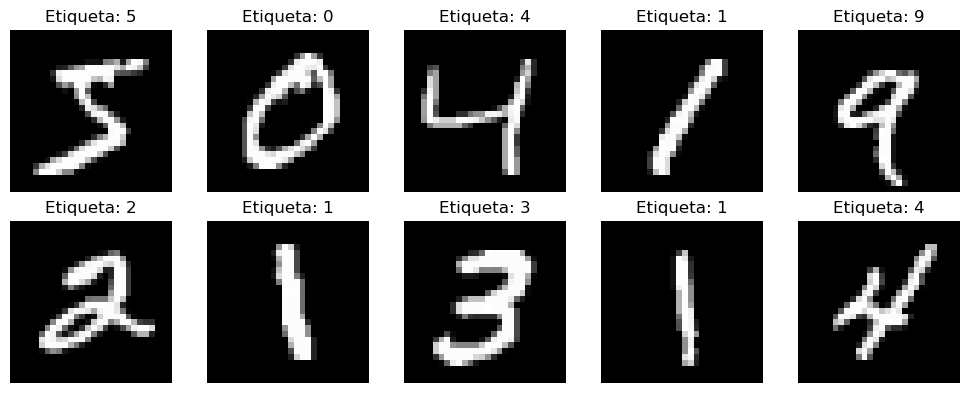

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), range(10)):
    image, label = train_dataset[idx]
    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(f'Etiqueta: {label}')
    ax.axis('off')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ejemplos_mnist.png', dpi=150)
plt.show()

## 5. Definición del modelo convolucional

Definimos una red convolucional muy simple:

1. La entrada tiene un canal, porque MNIST está en escala de grises.
2. La capa `Conv2d` tiene 10 filtros, uno por cada clase posible.
3. El tamaño del kernel es `28 × 28`, por lo que cada filtro cubre toda la imagen.
4. La salida se aplana para obtener un vector de 10 valores.
5. Aplicamos `log_softmax`, que convierte esos valores en log-probabilidades.

Este diseño no es el CNN típico con varias capas pequeñas, pero es muy interesante didácticamente porque permite visualizar los filtros aprendidos como plantillas globales para cada dígito.

In [5]:
class CNN(nn.Module):
    """Red convolucional mínima para clasificar MNIST.

    La red aplica 10 filtros de tamaño 28x28 sobre cada imagen. Como cada filtro
    cubre toda la imagen, la salida es un vector de 10 puntuaciones, una por clase.
    """

    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=10,
            kernel_size=28,
            bias=False
        )

    def forward(self, x):
        # Aplicamos la convolución. La salida tiene forma: batch_size x 10 x 1 x 1
        x = self.conv1(x)

        # Convertimos la salida a forma: batch_size x 10
        x = torch.flatten(x, 1)

        # Log-probabilidades para las 10 clases.
        output = F.log_softmax(x, dim=1)
        return output

model = CNN().to(device)
print(model)

CNN(
  (conv1): Conv2d(1, 10, kernel_size=(28, 28), stride=(1, 1), bias=False)
)


## 6. Funciones de entrenamiento y evaluación

La función de entrenamiento actualiza los pesos del modelo usando descenso por gradiente. La función de evaluación calcula la pérdida media y la precisión sobre el conjunto de test sin modificar los pesos.

Usamos `nll_loss` porque la red devuelve log-probabilidades mediante `log_softmax`.

In [10]:
def train(model, device, train_loader, optimizer, epoch):
    """Entrena el modelo durante una época."""
    model.train()
    running_loss = 0.0

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        # Reiniciamos los gradientes acumulados del batch anterior
        optimizer.zero_grad()

        # Forward pass: predicción del modelo
        output = model(data)

        # Cálculo de la pérdida
        loss = F.nll_loss(output, target)

        # Backpropagation y actualización de pesos
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx % 1000 == 0:
            print(
                f'Época {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} '
                f'({100. * batch_idx / len(train_loader):.0f}%)]	Pérdida: {loss.item():.6f}'
            )

    average_loss = running_loss / len(train_loader)
    return average_loss


def test(model, device, test_loader):
    """Evalúa el modelo sobre el conjunto de test."""
    model.eval()
    test_loss = 0.0
    correct = 0

    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)

            test_loss += F.nll_loss(output, target, reduction='sum').item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_targets.extend(target.cpu().numpy().tolist())
            all_predictions.extend(pred.squeeze().cpu().numpy().tolist())

    test_loss /= len(test_loader.dataset)
    accuracy = correct / len(test_loader.dataset)

    print(
    f'Test: pérdida media: {test_loss:.4f}, '
    f'precisión: {correct}/{len(test_loader.dataset)} '
    f'({100. * accuracy:.2f}%)'
        )

    return test_loss, accuracy, all_targets, all_predictions

## 7. Optimizador y scheduler

Utilizamos `Adadelta`, un optimizador adaptativo. Además, `StepLR` reduce la tasa de aprendizaje al final de cada época multiplicándola por `0.7`. Esta reducción progresiva permite que el entrenamiento haga ajustes cada vez más finos.

In [11]:
optimizer = optim.Adadelta(model.parameters(), lr=LEARNING_RATE)
scheduler = StepLR(optimizer, step_size=1, gamma=LR_GAMMA)

loss_list = []
test_loss_list = []
accuracy_list = []
learning_rates = []

## 8. Bucle de entrenamiento

Entrenamos durante varias épocas. Al final de cada época:

- evaluamos el modelo sobre el conjunto de test;
- guardamos métricas intermedias;
- guardamos un checkpoint del modelo;
- actualizamos la tasa de aprendizaje.

In [20]:
loss_list = []
test_loss_list = []
accuracy_list = []

for epoch in range(1, EPOCHS + 1):
    current_lr = optimizer.param_groups[0]['lr']
    learning_rates.append(current_lr)
    print(f'=== Época {epoch}/{EPOCHS} | learning rate = {current_lr:.6f} ===')

    train_loss = train(model, device, train_loader, optimizer, epoch)
    test_loss, accuracy, targets, predictions = test(model, device, test_loader)

    loss_list.append(train_loss)
    test_loss_list.append(test_loss)
    accuracy_list.append(accuracy)

    # Guardamos checkpoint intermedio para poder recuperar el modelo en esta época
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'train_loss': train_loss,
        'test_loss': test_loss,
        'accuracy': accuracy
    }
    torch.save(checkpoint, CHECKPOINT_DIR / f'checkpoint_epoch_{epoch:02d}.pt')

    scheduler.step()

# Guardamos el modelo final
model_path = OUTPUT_DIR / 'modelo_final_mnist_convnet.pt'
torch.save(model.state_dict(), model_path)
print(f'Modelo final guardado en: {model_path}')

=== Época 1/15 | learning rate = 0.000023 ===
Época 1 [0/60000 (0%)]	Pérdida: 0.326091
Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
=== Época 2/15 | learning rate = 0.000016 ===
Época 2 [0/60000 (0%)]	Pérdida: 0.352674
Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
=== Época 3/15 | learning rate = 0.000011 ===
Época 3 [0/60000 (0%)]	Pérdida: 0.245385
Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
=== Época 4/15 | learning rate = 0.000008 ===
Época 4 [0/60000 (0%)]	Pérdida: 0.211412
Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
=== Época 5/15 | learning rate = 0.000005 ===
Época 5 [0/60000 (0%)]	Pérdida: 0.181948
Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
=== Época 6/15 | learning rate = 0.000004 ===
Época 6 [0/60000 (0%)]	Pérdida: 0.302690
Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
=== Época 7/15 | learning rate = 0.000003 ===
Época 7 [0/60000 (0%)]	Pérdida: 0.238624
Test: pérdida media: 0.2760, pr

## 9. Guardado de métricas

Exportamos las métricas a un archivo CSV. Esto permite analizarlas posteriormente en Python, Excel o cualquier otra herramienta.

In [21]:
metrics_path = OUTPUT_DIR / 'metricas_entrenamiento.csv'

with open(metrics_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'train_loss', 'test_loss', 'accuracy', 'learning_rate'])
    for i in range(EPOCHS):
        writer.writerow([i + 1, loss_list[i], test_loss_list[i], accuracy_list[i], learning_rates[i]])

print(f'Métricas guardadas en: {metrics_path}')

Métricas guardadas en: resultados_mnist_convnet/metricas_entrenamiento.csv


## 10. Visualización de la evolución del entrenamiento

Representamos la pérdida de entrenamiento, la pérdida de test y la precisión. Estas curvas ayudan a detectar problemas como infraentrenamiento, sobreajuste o aprendizaje inestable.

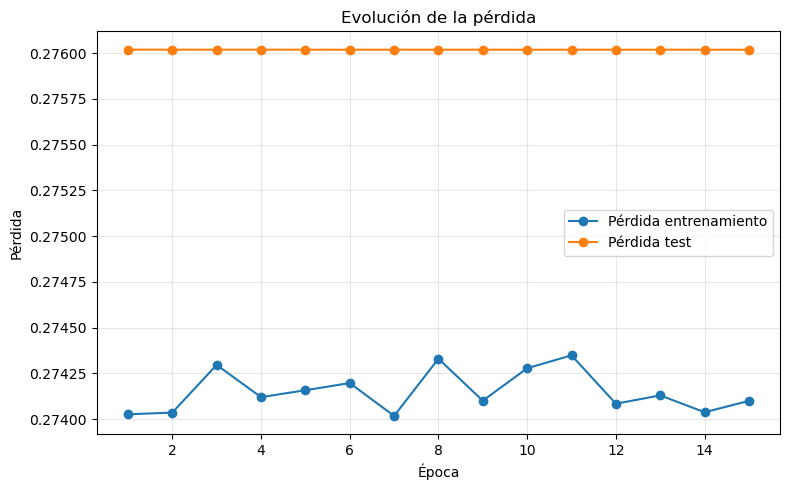

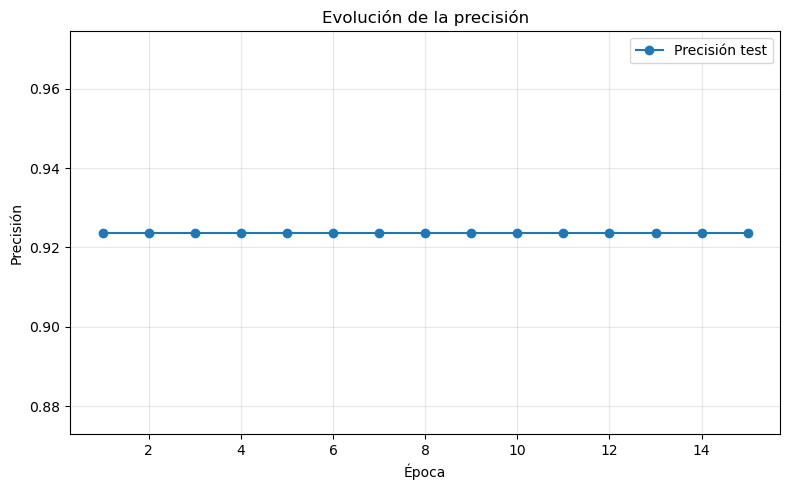

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), loss_list, marker='o', label='Pérdida entrenamiento')
plt.plot(range(1, EPOCHS + 1), test_loss_list, marker='o', label='Pérdida test')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curva_perdida.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), accuracy_list, marker='o', label='Precisión test')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.title('Evolución de la precisión')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'curva_precision.png', dpi=150)
plt.show()

## 11. Visualización de los filtros aprendidos

Como la red solo tiene una capa convolucional, los filtros aprendidos son especialmente interpretables. Cada filtro puede verse como una plantilla asociada a una de las 10 clases.

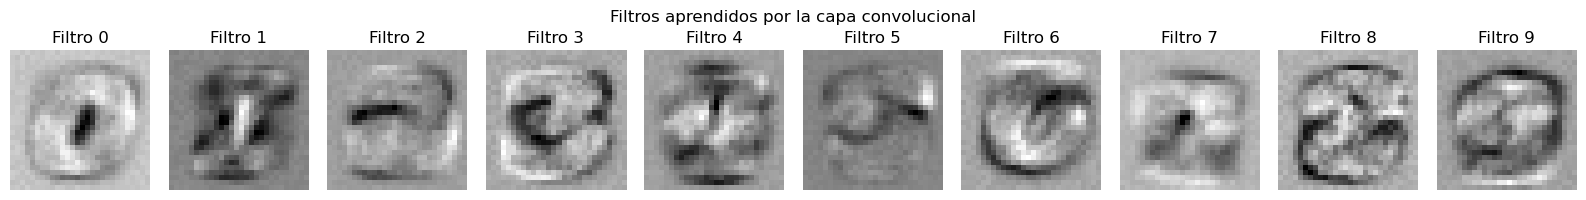

In [23]:
state_dict = model.state_dict()
filters = state_dict['conv1.weight'].detach().cpu().numpy()

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
for i in range(10):
    axes[i].imshow(filters[i, 0], cmap='gray')
    axes[i].set_title(f'Filtro {i}')
    axes[i].axis('off')

plt.suptitle('Filtros aprendidos por la capa convolucional')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'filtros_aprendidos.png', dpi=150)
plt.show()

# Guardamos también los filtros como array NumPy
np.save(OUTPUT_DIR / 'filtros_conv1.npy', filters)

## 12. Predicciones y errores del modelo

Guardamos las predicciones finales y visualizamos algunos errores. Este paso es útil para interpretar qué clases confunde más el modelo.

In [24]:
# Evaluación final para obtener etiquetas y predicciones
_, final_accuracy, final_targets, final_predictions = test(model, device, test_loader)

predictions_path = OUTPUT_DIR / 'predicciones_test.csv'
with open(predictions_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['indice', 'etiqueta_real', 'prediccion'])
    for idx, (target, pred) in enumerate(zip(final_targets, final_predictions)):
        writer.writerow([idx, target, pred])

print(f'Predicciones guardadas en: {predictions_path}')
print(f'Precisión final: {100 * final_accuracy:.2f}%')

Test: pérdida media: 0.2760, precisión: 9237/10000 (92.37%)
Predicciones guardadas en: resultados_mnist_convnet/predicciones_test.csv
Precisión final: 92.37%


Número de errores en test: 763


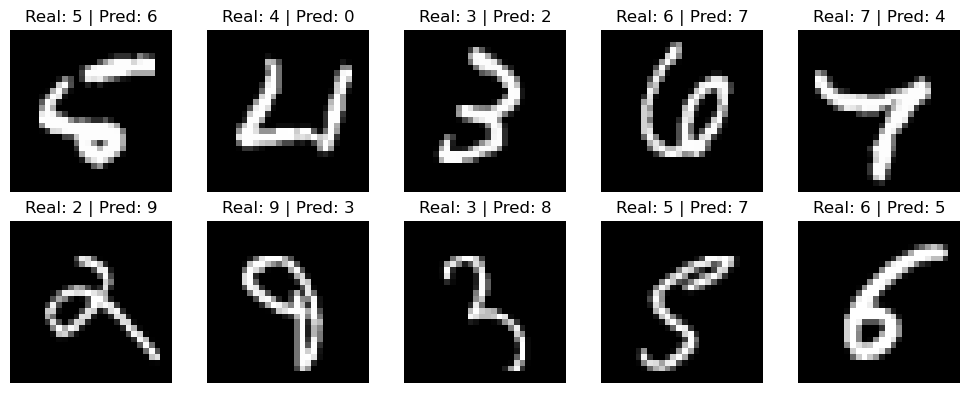

In [25]:
# Localizamos algunos errores de clasificación
errors = [i for i, (t, p) in enumerate(zip(final_targets, final_predictions)) if t != p]
print(f'Número de errores en test: {len(errors)}')

num_errors_to_show = min(10, len(errors))

if num_errors_to_show > 0:
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax, idx in zip(axes.ravel(), errors[:num_errors_to_show]):
        image, true_label = test_dataset[idx]
        predicted_label = final_predictions[idx]
        ax.imshow(image.squeeze(), cmap='gray')
        ax.set_title(f'Real: {true_label} | Pred: {predicted_label}')
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'ejemplos_errores.png', dpi=150)
    plt.show()
else:
    print('No se han encontrado errores en los primeros resultados evaluados.')

## 13. Conclusión

Este notebook muestra una aproximación sencilla a la clasificación de MNIST mediante una red convolucional mínima. Aunque el modelo es mucho más simple que una CNN profunda convencional, permite entender con claridad el flujo completo de trabajo:

1. carga y transformación de datos;
2. definición de arquitectura;
3. entrenamiento y validación;
4. guardado de resultados intermedios;
5. análisis de filtros, métricas y errores.

Desde un punto de vista didáctico, el aspecto más interesante es que los filtros aprendidos pueden interpretarse visualmente como patrones globales asociados a las clases del problema.